In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-07-21/nde_experiences.csv"
df = pd.read_csv(url)
df["post_date"] = pd.to_datetime(df["post_date"], errors="coerce")
df["exp_date"] = pd.to_datetime(df["exp_date"], errors="coerce")
ai_cols = [c for c in df.columns if c.startswith("ai_")]
df.shape

(589, 18)

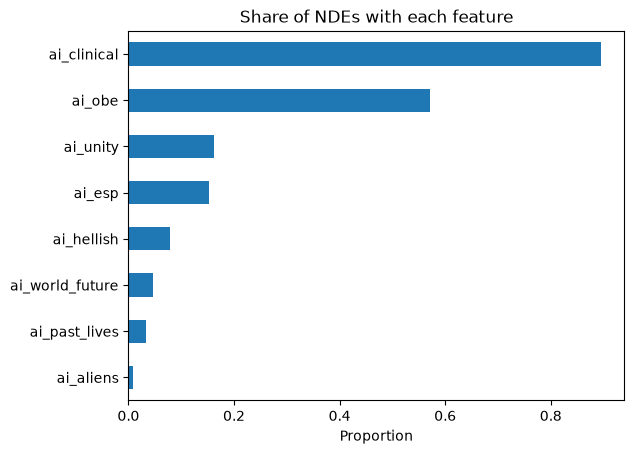

In [2]:
# How common each feature is
prev = df[ai_cols].mean().sort_values()
prev.plot.barh(title="Share of NDEs with each feature")
plt.xlabel("Proportion"); plt.show()

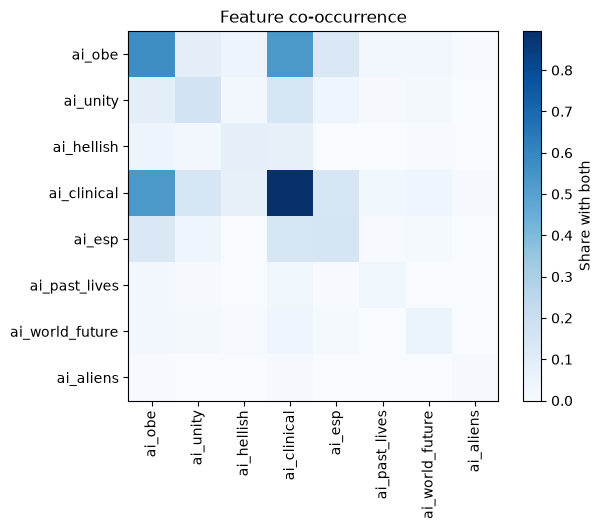

In [3]:
# Co-occurrence matrix: % of rows with both features
X = df[ai_cols].astype(int)
co = (X.T @ X) / len(df)
plt.imshow(co, cmap="Blues")
plt.xticks(range(len(ai_cols)), ai_cols, rotation=90)
plt.yticks(range(len(ai_cols)), ai_cols)
plt.colorbar(label="Share with both"); plt.title("Feature co-occurrence"); plt.show()

In [4]:
# OBE vs ESP / unity
from scipy.stats import chi2_contingency
for f in ["ai_esp", "ai_unity"]:
    tab = pd.crosstab(df["ai_obe"], df[f])
    chi2, p, _, _ = chi2_contingency(tab)
    print(f, "\n", pd.crosstab(df["ai_obe"], df[f], normalize="index").round(2), f"\np = {p:.3f}\n")

ai_esp 
 ai_esp  False  True 
ai_obe              
False    0.95   0.05
True     0.77   0.23 
p = 0.000

ai_unity 
 ai_unity  False  True 
ai_obe                
False      0.82   0.18
True       0.85   0.15 
p = 0.440

